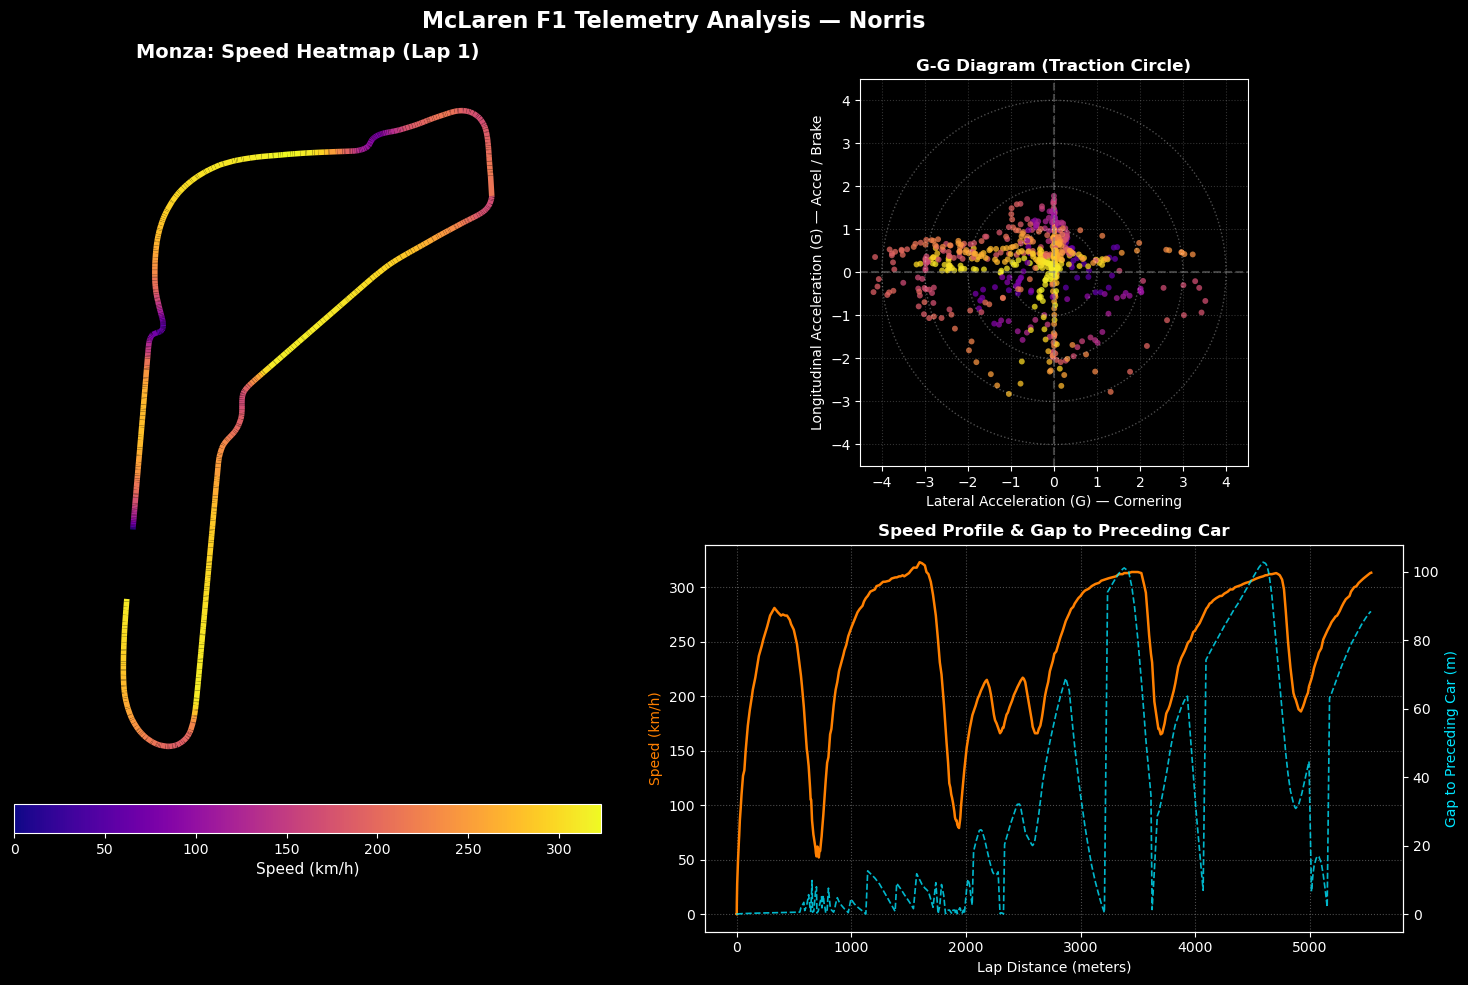

In [20]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection

# 1. Load telemetry data from the local JSON file
with open('1_tel.json', 'r') as f:
    raw_data = json.load(f)

# Extract telemetry dictionary into a DataFrame
tel = raw_data['tel']
df = pd.DataFrame(tel)

# 2. Configure dark racing theme
plt.style.use('dark_background')
fig = plt.figure(figsize=(16, 10))

# Layout: 2 rows, 2 columns (Track map on the left, G-G and Speed profiles on the right)
gs = fig.add_gridspec(2, 2, width_ratios=[1.2, 1], height_ratios=[1, 1])
ax_track = fig.add_subplot(gs[:, 0])
ax_gg = fig.add_subplot(gs[0, 1])
ax_speed = fig.add_subplot(gs[1, 1])

# -------------------------------------------------------------
# PANEL 1: Monza 2D Track Map with Speed Colormap
# -------------------------------------------------------------
points = np.array([df['x'], df['y']]).T.reshape(-1, 1, 2)
segments = np.concatenate([points[:-1], points[1:]], axis=1)

norm = plt.Normalize(df['speed'].min(), df['speed'].max())
lc = LineCollection(segments, cmap='plasma', norm=norm, linewidth=4)
lc.set_array(df['speed'])

line = ax_track.add_collection(lc)
ax_track.autoscale()
ax_track.set_aspect('equal')
ax_track.axis('off')
ax_track.set_title("Monza: Speed Heatmap (Lap 1)", fontsize=14, weight='bold', pad=15)

# Speed Colorbar
cbar = fig.colorbar(line, ax=ax_track, orientation='horizontal', pad=0.03, shrink=0.7)
cbar.set_label('Speed (km/h)', fontsize=11)

# -------------------------------------------------------------
# PANEL 2: G-G Diagram (Traction & Cornering Limits)
# Convert acceleration from m/s^2 to g (/ 9.81)
# -------------------------------------------------------------
g_lat = df['acc_y'] / 9.81   # Lateral acceleration (cornering)
g_long = df['acc_x'] / 9.81  # Longitudinal acceleration (accel / brake)

sc = ax_gg.scatter(g_lat, g_long, c=df['speed'], cmap='plasma', s=18, alpha=0.75, edgecolors='none')
ax_gg.axhline(0, color='gray', linestyle='--', alpha=0.5)
ax_gg.axvline(0, color='gray', linestyle='--', alpha=0.5)

# Draw 1G, 2G, 3G, 4G concentric circles
for r in [1, 2, 3, 4]:
    circle = plt.Circle((0, 0), r, color='white', fill=False, linestyle=':', alpha=0.3)
    ax_gg.add_patch(circle)

ax_gg.set_xlabel('Lateral Acceleration (G) — Cornering', fontsize=10)
ax_gg.set_ylabel('Longitudinal Acceleration (G) — Accel / Brake', fontsize=10)
ax_gg.set_title('G-G Diagram (Traction Circle)', fontsize=12, weight='bold')
ax_gg.set_xlim(-4.5, 4.5)
ax_gg.set_ylim(-4.5, 4.5)
ax_gg.set_aspect('equal')
ax_gg.grid(True, linestyle=':', alpha=0.2)

# -------------------------------------------------------------
# PANEL 3: Speed Profile & Lap 1 Traffic Management
# -------------------------------------------------------------
ax_speed.plot(df['distance'], df['speed'], color='#FF8000', label='Lando Norris (Speed)', lw=1.8)
ax_speed.set_ylabel('Speed (km/h)', color='#FF8000', fontsize=10)
ax_speed.set_xlabel('Lap Distance (meters)', fontsize=10)
ax_speed.grid(True, linestyle=':', alpha=0.3)

# Secondary Y-axis: Distance to Driver Ahead
ax_traffic = ax_speed.twinx()
ax_traffic.plot(df['distance'], df['DistanceToDriverAhead'], color='#00E5FF', lw=1.2, ls='--', alpha=0.8, label='Distance to Car Ahead (m)')
ax_traffic.set_ylabel('Gap to Preceding Car (m)', color='#00E5FF', fontsize=10)

ax_speed.set_title('Speed Profile & Gap to Preceding Car', fontsize=12, weight='bold')

plt.suptitle(f"McLaren F1 Telemetry Analysis — {raw_data.get('dataKey', 'Norris')}", fontsize=16, weight='bold', y=0.98)
plt.tight_layout()
plt.savefig('telemetry_dashboard.png', dpi=300, bbox_inches='tight')
plt.show()